Processing SIDM_AHFout...
Processing CDM_AHFout...


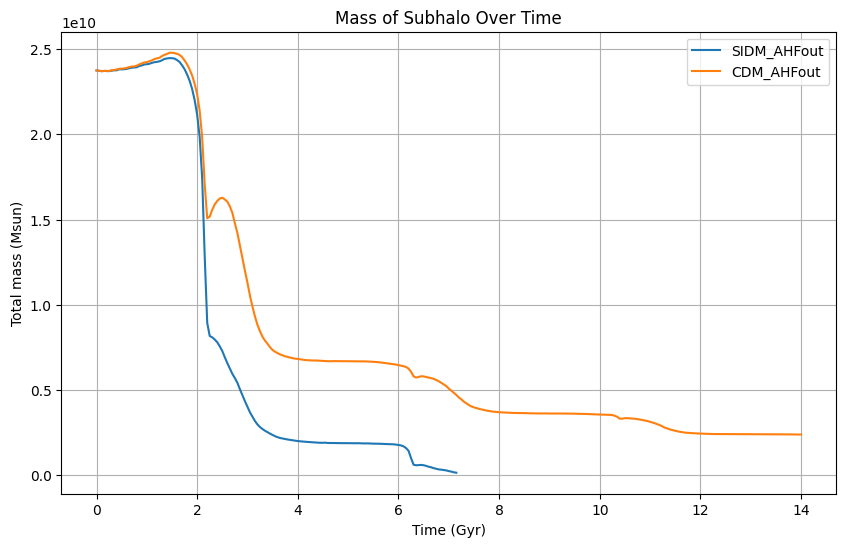

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ==================== CONFIG & CONSTANTS ====================
BASE_PATH = "./Data/"
# List your folder names here
FOLDERS = ["SIDM_AHFout", "CDM_AHFout"] 
TOTAL_SNAPS = 280
HOST_CENTER = np.array([10000.0, 10000.0, 10000.0])

# ==================== HELPER FUNCTION ====================
def read_subhalo_mass(folder_name):
    """Reads snapshot data from a specific folder."""
    masses = []
    radius = []
    ahf_dir = os.path.join(BASE_PATH, folder_name)
    
    for i in range(TOTAL_SNAPS + 1):
        path = os.path.join(ahf_dir, f"{i}-halos")
        if not os.path.exists(path): continue
        
        with open(path, 'r') as f:
            lines = f.readlines()
            for line in lines[1:]:
                cols = line.split()
                # pos = np.array([float(cols[5]), float(cols[6]), float(cols[7])])
                masses.append(float(cols[3]))
                radius.append(float(cols[11]))
                # print(pos)  # Debug: print the last read position
    return np.array(masses), np.array(radius)

# ==================== PROCESSING MULTIPLE FOLDERS ====================
all_sims = {}
all_sims_r = {}

for folder in FOLDERS:
    print(f"Processing {folder}...")
    data = read_subhalo_mass(folder)[0]
    r_data = read_subhalo_mass(folder)[1]
    all_sims[folder] = data
    all_sims_r[folder] = r_data

# snapshot with corresponding time in Gyr
DT_SNAP = 0.05

plt.figure(figsize=(10, 6))
for folder, masses in all_sims.items():
    time = np.arange(len(masses)) * DT_SNAP
    plt.plot(time, masses, label=folder.split('/')[0])  # Convert to e10 Msun

plt.xlabel("Time (Gyr)")
plt.ylabel("Total mass (Msun)")
plt.title("Mass of Subhalo Over Time")
plt.legend()
plt.grid()
plt.show()


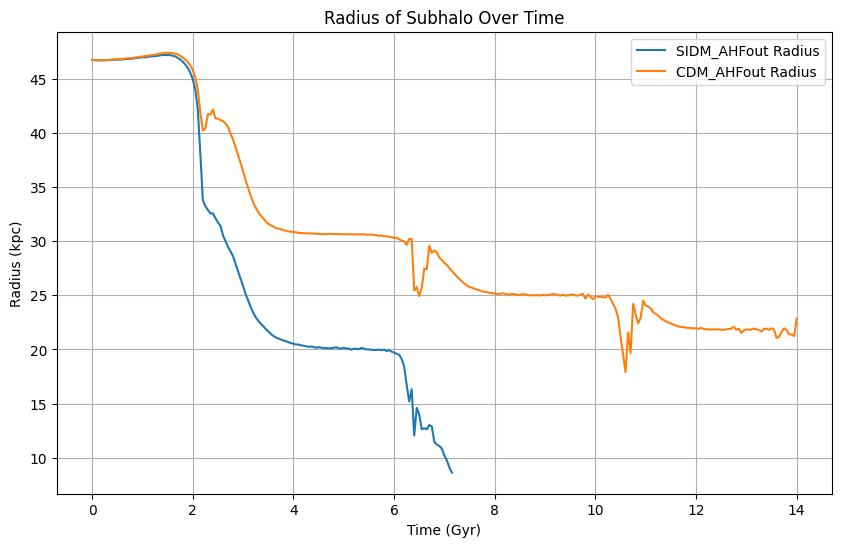

In [12]:
# plot radius as well
plt.figure(figsize=(10, 6))
for folder, r_data in all_sims_r.items():
    time = np.arange(len(r_data)) * DT_SNAP
    plt.plot(time, r_data, label=f"{folder.split('/')[0]} Radius")  # Plot radius as well   
plt.xlabel("Time (Gyr)")
plt.ylabel("Radius (kpc)")
plt.title("Radius of Subhalo Over Time")
plt.legend()
plt.grid()
plt.show()